# 🎓 Encontro 2 — Geometria Projetiva e o Efeito Scanner

## Transformação de perspectiva e retificação de documentos

Na Aula 2, usamos o Sobel para destacar mudanças de intensidade, encontrar as bordas de objetos e, ao final, extrair as quatro extremidades de um documento fotografado. Hoje vamos dar o próximo passo: usar essas quatro quinas para transformar a fotografia inclinada em uma imagem plana, como se ela tivesse sido capturada por um scanner.

Aplicativos como Google Drive, CamScanner e Adobe Scan fazem exatamente essa ideia em seus primeiros estágios. Nesta aula, vamos abrir essa caixa-preta e implementar a matemática usando somente `numpy` e `matplotlib`.

### Objetivos

1. Entender coordenadas homogêneas e por que elas representam perspectiva.
2. Construir, a partir de matrizes elementares, a intuição de como translação, rotação, escala, cisalhamento e perspectiva distorcem um polígono — e por que só a perspectiva quebra o paralelismo.
3. Calcular uma homografia `3 × 3` com DLT e SVD.
4. Implementar inverse warping e interpolação Nearest Neighbor.
5. Montar um pipeline de retificação de documento reaproveitando as quinas calculadas na Aula 2.
6. Validar cada etapa com testes numéricos e visualizações.

> **Importante:** nesta primeira versão, as quatro quinas vêm do arquivo `fragments/extremidades_objeto.txt`, gerado ao final da Aula 2 a partir do mapa de bordas do Sobel — não digitamos números manualmente, mas também não implementamos um detector de cantos geral. O heurístico usado (os 4 pontos mais extremos em cada direção do plano) funciona neste caso porque o documento fotografado é convexo; transformar um mapa de bordas qualquer em quatro cantos robustos exige uma etapa adicional de detecção de contornos e interseção de retas — veja os exercícios ao final do notebook.


In [1]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['figure.facecolor'] = 'white'
np.set_printoptions(precision=4, suppress=True)


def carregar_imagem_rgb(caminho):
    """Carrega uma imagem como float64 RGB no intervalo [0, 1]."""
    imagem = mpimg.imread(caminho)

    if imagem.ndim == 2:
        imagem = np.stack([imagem, imagem, imagem], axis=-1)
    elif imagem.shape[-1] == 4:
        imagem = imagem[..., :3]

    imagem = imagem.astype(np.float64)
    if imagem.max() > 1.0:
        imagem /= 255.0

    return np.clip(imagem, 0.0, 1.0)


def mostrar_pontos(imagem, pontos, titulo):
    """Exibe uma imagem com quatro pontos [x, y] e o polígono fechado."""
    _fig, ax = plt.subplots(figsize=(9, 6))
    ax.imshow(imagem)
    pontos_fechados = np.vstack([pontos, pontos[0]])
    ax.plot(pontos_fechados[:, 0], pontos_fechados[:, 1], color='crimson', linewidth=2)
    ax.scatter(pontos[:, 0], pontos[:, 1], color='yellow', edgecolors='black', s=80, zorder=3)
    for indice, (x, y) in enumerate(pontos):
        ax.text(x + 8, y - 8, str(indice), color='black', fontsize=11,
                bbox={'facecolor': 'yellow', 'edgecolor': 'black', 'pad': 2})
    ax.set_title(titulo)
    ax.axis('off')
    plt.show()

## 1. O problema da perspectiva

Uma folha plana fotografada de frente continua sendo um retângulo. Quando a câmera se desloca para o lado ou para cima, porém, as linhas paralelas da folha continuam retas, mas os quatro cantos aparecem como um quadrilátero irregular.

A Aula 2 nos deu uma pista importante: o Sobel destaca as transições entre a folha e o fundo. Ao final daquela aula, já extraímos quatro pontos extremos do mapa de bordas (topo, direita, base, esquerda) e os salvamos em `fragments/extremidades_objeto.txt`. Nesta aula vamos **carregar esse arquivo diretamente** — sem detectar cantos do zero, sem chutar números novos — e usá-lo como ponto de partida para a geometria projetiva.

Adotaremos sempre esta ordem:

1. superior-esquerda;
2. superior-direita;
3. inferior-direita;
4. inferior-esquerda.

A ordem precisa ser a mesma nos pontos de origem e nos pontos de destino.


## 2. Coordenadas homogêneas

Em coordenadas cartesianas, um ponto é escrito como $p = (x, y)$. Uma transformação afim pode ser descrita por uma matriz `2 × 2` mais uma translação, mas a translação não cabe apenas em uma multiplicação matricial `2 × 2`.

A perspectiva acrescenta outro desafio: a divisão pela profundidade faz com que a transformação não seja linear no plano da imagem.

A solução é adicionar uma coordenada auxiliar $w$:

$$
\begin{bmatrix} x \\ y \end{bmatrix}
\longrightarrow
\begin{bmatrix} x \\ y \\ 1 \end{bmatrix}.
$$

Um ponto homogêneo representa o mesmo ponto que qualquer múltiplo não nulo dele. Por exemplo:

$$
\begin{bmatrix} 4 \\ 6 \\ 2 \end{bmatrix}
\sim
\begin{bmatrix} 2 \\ 3 \\ 1 \end{bmatrix}.
$$

Para voltar ao plano cartesiano, fazemos a de-homogeneização:

$$
(x, y) = \left(\frac{X}{W}, \frac{Y}{W}\right).
$$

In [2]:
def pontos_para_homogeneos(pontos):
    """Converte um array (N, 2) de pontos [x, y] para (N, 3)."""
    pontos = np.asarray(pontos, dtype=np.float64)
    if pontos.ndim != 2 or pontos.shape[1] != 2:
        raise ValueError('Esperado um array com shape (N, 2).')
    return np.hstack([pontos, np.ones((pontos.shape[0], 1))])


def pontos_para_cartesianos(pontos_homogeneos):
    """Divide as duas primeiras coordenadas pela coordenada homogênea W."""
    pontos_homogeneos = np.asarray(pontos_homogeneos, dtype=np.float64)
    if pontos_homogeneos.ndim != 2 or pontos_homogeneos.shape[1] != 3:
        raise ValueError('Esperado um array com shape (N, 3).')
    w = pontos_homogeneos[:, 2]
    if np.any(np.isclose(w, 0.0)):
        raise ValueError('Não é possível de-homogeneizar W próximo de zero.')
    return pontos_homogeneos[:, :2] / w[:, None]


def aplicar_homografia(pontos, homografia):
    """Aplica qualquer matriz 3x3 (afim ou projetiva) a pontos (N, 2), retornando pontos cartesianos (N, 2)."""
    pontos_h = pontos_para_homogeneos(pontos)
    transformados_h = (homografia @ pontos_h.T).T
    return pontos_para_cartesianos(transformados_h)


pontos_teste = np.array([[10, 20], [30, 40], [50, 60]], dtype=np.float64)
pontos_h = pontos_para_homogeneos(pontos_teste)
pontos_volta = pontos_para_cartesianos(pontos_h)

print('Pontos homogêneos:')
print(pontos_h)
print('\nErro máximo da ida e volta:', np.max(np.abs(pontos_teste - pontos_volta)))
assert np.allclose(pontos_teste, pontos_volta)


Pontos homogêneos:
[[10. 20.  1.]
 [30. 40.  1.]
 [50. 60.  1.]]

Erro máximo da ida e volta: 0.0


## 3. Transformações elementares e distorção de polígonos

Antes de resolver uma homografia geral por correspondência de pontos (Seção 4), vale a pena construir intuição com transformações mais simples. Toda transformação 2D pode ser escrita como uma matriz `3 × 3` atuando em coordenadas homogêneas — a diferença entre elas está em **quais entradas da matriz são diferentes de zero**:

$$
\underbrace{\begin{bmatrix} a & b & t_x \\ c & d & t_y \\ 0 & 0 & 1 \end{bmatrix}}_{\text{afim}}
\qquad\text{vs.}\qquad
\underbrace{\begin{bmatrix} a & b & t_x \\ c & d & t_y \\ p & q & 1 \end{bmatrix}}_{\text{projetiva}}
$$

Na matriz **afim**, a última linha é sempre $[0, 0, 1]$ — por isso $W$ é sempre $1$ e a de-homogeneização não faz nada ($u=U$, $v=V$): a transformação é **linear** em $(x,y)$. Isso implica uma propriedade importante: **transformações afins sempre preservam o paralelismo de retas**. Assim que $p$ ou $q$ deixam de ser zero, $W$ passa a depender de $(x,y)$, a divisão $U/W,\ V/W$ deixa de ser linear, e retas paralelas podem convergir — é exatamente esse termo que cria o efeito de perspectiva que motiva toda esta aula.

Para deixar rotação e cisalhamento visualmente óbvios (um quadrado sozinho esconde essas distorções por simetria), vamos usar um polígono didático: uma "casa" (um quadrado com um telhado triangular).


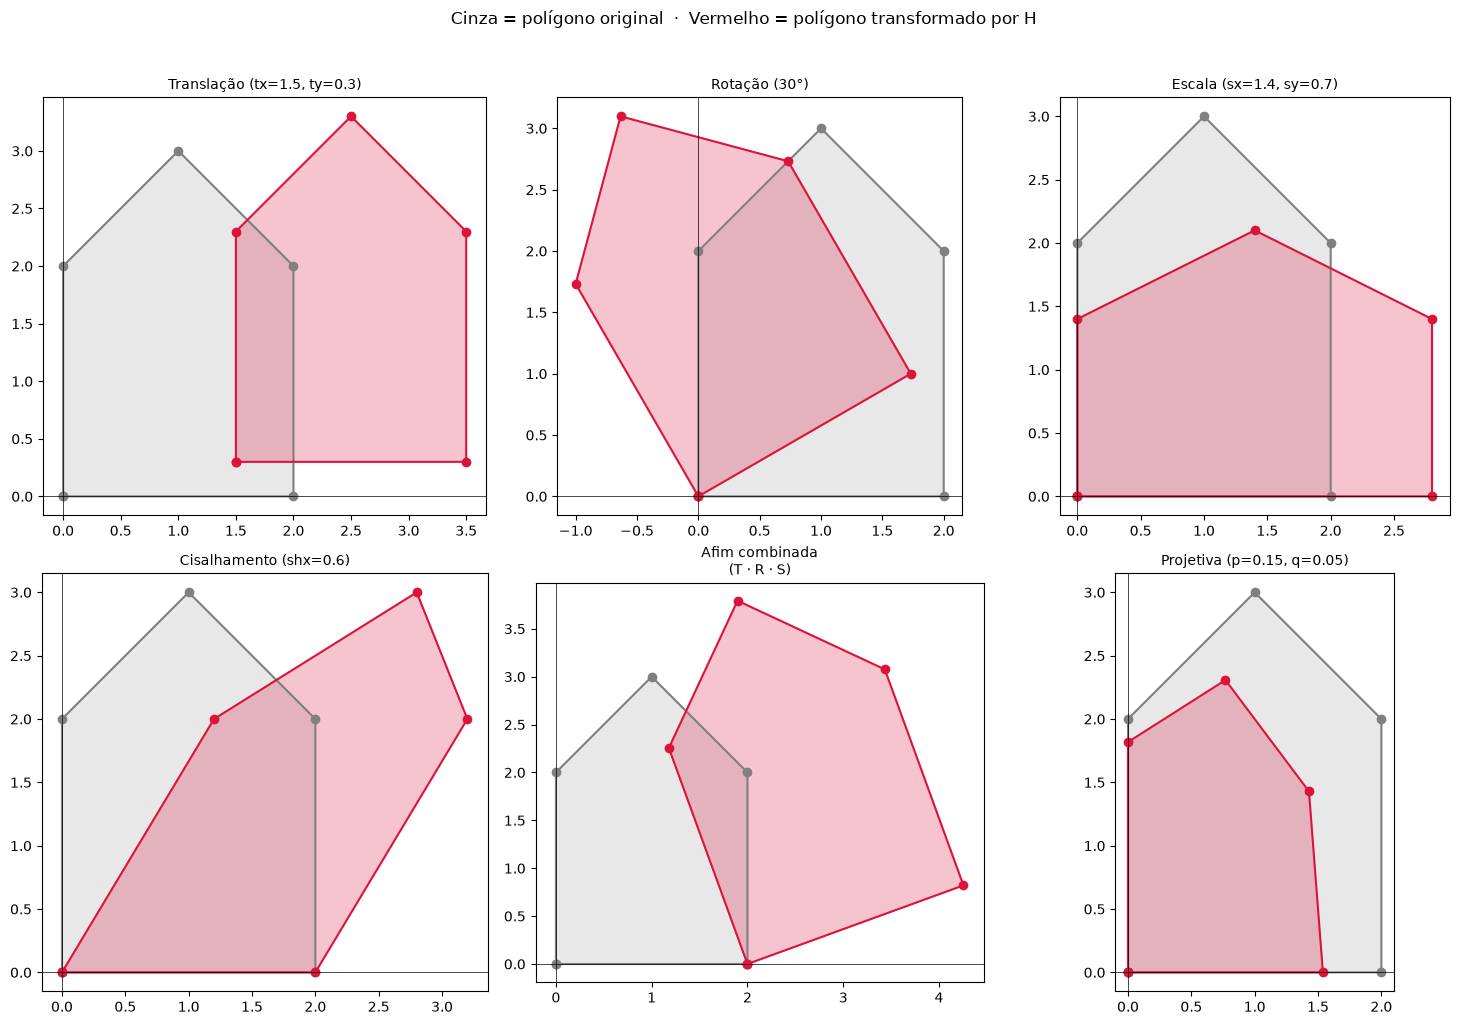

In [3]:
def poligono_casa():
    """Polígono didático (quadrado + telhado): a assimetria evidencia rotação e cisalhamento."""
    return np.array([
        [0.0, 0.0],
        [2.0, 0.0],
        [2.0, 2.0],
        [1.0, 3.0],
        [0.0, 2.0],
    ])


def matriz_translacao(tx, ty):
    return np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], dtype=np.float64)


def matriz_rotacao(graus):
    theta = np.radians(graus)
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]], dtype=np.float64)


def matriz_escala(sx, sy):
    return np.array([[sx, 0, 0], [0, sy, 0], [0, 0, 1]], dtype=np.float64)


def matriz_cisalhamento(shx, shy):
    return np.array([[1, shx, 0], [shy, 1, 0], [0, 0, 1]], dtype=np.float64)


def matriz_projetiva(p, q):
    """Parte da identidade e altera só a linha de perspectiva -- é o que distingue afim de projetiva."""
    homografia = np.eye(3)
    homografia[2, 0], homografia[2, 1] = p, q
    return homografia


def plotar_transformacao(poligono, homografia, titulo, ax):
    """Sobrepõe o polígono original (cinza) e sua imagem por H (vermelho) no mesmo eixo."""
    transformado = aplicar_homografia(poligono, homografia)

    original_fechado = np.vstack([poligono, poligono[0]])
    transformado_fechado = np.vstack([transformado, transformado[0]])

    ax.fill(*original_fechado.T, color='lightgray', alpha=0.5)
    ax.plot(*original_fechado.T, color='gray', marker='o')
    ax.fill(*transformado_fechado.T, color='crimson', alpha=0.25)
    ax.plot(*transformado_fechado.T, color='crimson', marker='o')

    ax.set_title(titulo, fontsize=10)
    ax.set_aspect('equal')
    ax.axhline(0, color='black', linewidth=0.5)
    ax.axvline(0, color='black', linewidth=0.5)
    return transformado


casa = poligono_casa()
transformacoes = {
    'Translação (tx=1.5, ty=0.3)': matriz_translacao(1.5, 0.3),
    'Rotação (30°)': matriz_rotacao(30),
    'Escala (sx=1.4, sy=0.7)': matriz_escala(1.4, 0.7),
    'Cisalhamento (shx=0.6)': matriz_cisalhamento(0.6, 0.0),
    'Afim combinada\n(T · R · S)': matriz_translacao(2, 0) @ matriz_rotacao(20) @ matriz_escala(1.2, 1.2),
    'Projetiva (p=0.15, q=0.05)': matriz_projetiva(0.15, 0.05),
}

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for ax, (titulo, homografia) in zip(axs.ravel(), transformacoes.items()):
    plotar_transformacao(casa, homografia, titulo, ax)
plt.suptitle('Cinza = polígono original  ·  Vermelho = polígono transformado por H', y=1.02)
plt.tight_layout()
plt.show()


### 3.1 A ordem da multiplicação importa

Diferente de números, matrizes quase nunca comutam: $A \cdot B \neq B \cdot A$. Girar e depois transladar não é o mesmo que transladar e depois girar — a ordem em que compomos as matrizes muda o resultado geométrico.


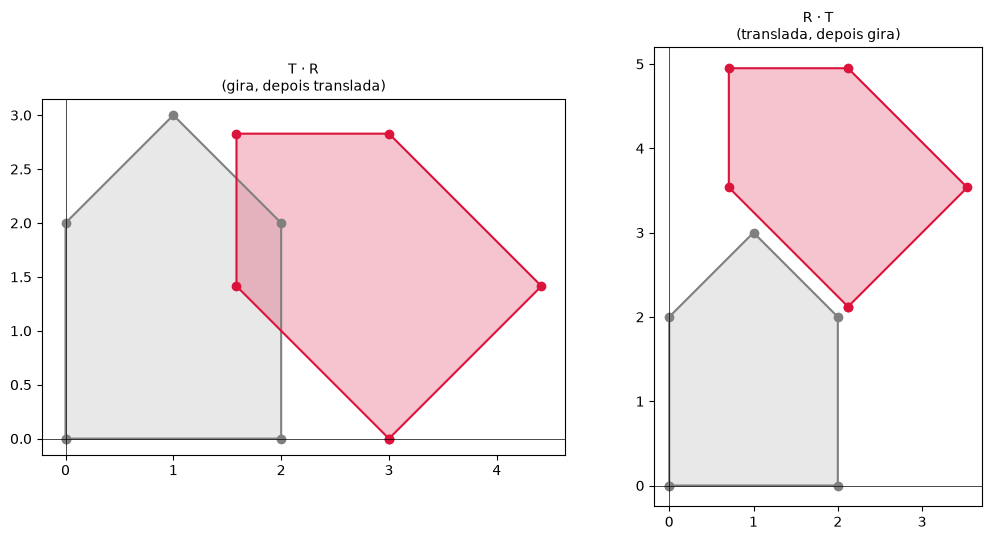

As duas matrizes compostas são iguais? False


In [4]:
H_rotaciona_depois_translada = matriz_translacao(3, 0) @ matriz_rotacao(45)
H_translada_depois_rotaciona = matriz_rotacao(45) @ matriz_translacao(3, 0)

fig, axs = plt.subplots(1, 2, figsize=(11, 5.5))
plotar_transformacao(casa, H_rotaciona_depois_translada, 'T · R\n(gira, depois translada)', axs[0])
plotar_transformacao(casa, H_translada_depois_rotaciona, 'R · T\n(translada, depois gira)', axs[1])
plt.tight_layout()
plt.show()

print('As duas matrizes compostas são iguais?', np.allclose(H_rotaciona_depois_translada, H_translada_depois_rotaciona))
assert not np.allclose(H_rotaciona_depois_translada, H_translada_depois_rotaciona)


### 3.2 O teste que separa afim de projetiva: paralelismo

Uma forma objetiva (não apenas visual) de diferenciar as duas famílias: aplicamos a transformação a um retângulo e verificamos se os lados opostos continuam paralelos. Dois vetores $\vec{d_1}$ e $\vec{d_2}$ são paralelos quando seu produto vetorial 2D (um escalar) é zero:

$$ \vec{d_1} \times \vec{d_2} = d_{1x}\, d_{2y} - d_{1y}\, d_{2x} = 0 $$

Isso conecta diretamente com a Seção 4: uma homografia geral (DLT) tem $h_{31}, h_{32}$ livres — por isso ela consegue mapear um retângulo em qualquer quadrilátero convexo, algo que nenhuma composição de translação, rotação, escala e cisalhamento jamais conseguiria.


Lados opostos continuam paralelos (transformação AFIM)?      True
Lados opostos continuam paralelos (transformação PROJETIVA)? False


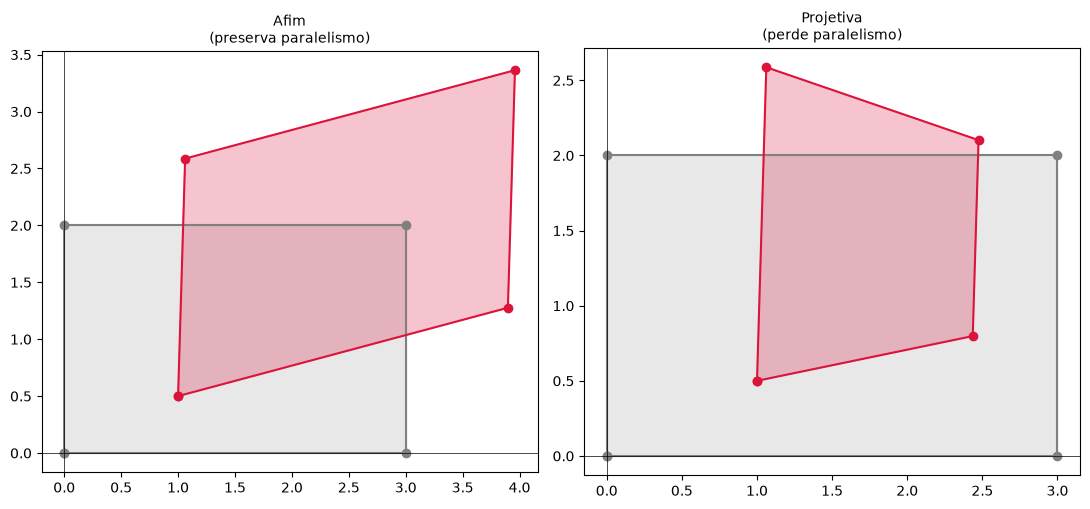

In [5]:
def sao_paralelas(p1, p2, p3, p4, tol=1e-6):
    """Compara o produto vetorial 2D das direções p1->p2 e p3->p4."""
    d1, d2 = p2 - p1, p4 - p3
    return abs(d1[0] * d2[1] - d1[1] * d2[0]) < tol


retangulo = np.array([[0, 0], [3, 0], [3, 2], [0, 2]], dtype=np.float64)

H_afim = matriz_translacao(1, 0.5) @ matriz_rotacao(15) @ matriz_cisalhamento(0.3, 0.0)
H_projetiva = H_afim.copy()
H_projetiva[2, 0] = 0.2  # adiciona apenas o termo de perspectiva, nada mais muda

retangulo_afim = aplicar_homografia(retangulo, H_afim)
retangulo_projetivo = aplicar_homografia(retangulo, H_projetiva)

print('Lados opostos continuam paralelos (transformação AFIM)?     ',
      sao_paralelas(retangulo_afim[0], retangulo_afim[1], retangulo_afim[3], retangulo_afim[2]))
print('Lados opostos continuam paralelos (transformação PROJETIVA)?',
      sao_paralelas(retangulo_projetivo[0], retangulo_projetivo[1], retangulo_projetivo[3], retangulo_projetivo[2]))

fig, axs = plt.subplots(1, 2, figsize=(11, 5.5))
plotar_transformacao(retangulo, H_afim, 'Afim\n(preserva paralelismo)', axs[0])
plotar_transformacao(retangulo, H_projetiva, 'Projetiva\n(perde paralelismo)', axs[1])
plt.tight_layout()
plt.show()

assert sao_paralelas(retangulo_afim[0], retangulo_afim[1], retangulo_afim[3], retangulo_afim[2])
assert not sao_paralelas(retangulo_projetivo[0], retangulo_projetivo[1], retangulo_projetivo[3], retangulo_projetivo[2])


## 4. Homografia e o método DLT

A transformação projetiva entre o ponto de origem $(x, y)$ e o ponto de destino $(u, v)$ é representada por uma matriz $H$:

$$
\begin{bmatrix}
U \\ V \\ W
\end{bmatrix}
=
H
\begin{bmatrix}
x \\ y \\ 1
\end{bmatrix},
\qquad
H =
\begin{bmatrix}
 h_{11} & h_{12} & h_{13} \\
 h_{21} & h_{22} & h_{23} \\
 h_{31} & h_{32} & h_{33}
\end{bmatrix}.
$$

O ponto final é obtido por:

$$
 u = \frac{U}{W}, \qquad v = \frac{V}{W}.
$$

Na Seção 3 vimos essa mesma matriz em casos particulares (afim, quando $h_{31}=h_{32}=0$). Agora queremos o caso geral: dados quatro pares de pontos correspondentes, encontrar os 9 elementos de $H$.

A matriz tem 9 elementos, mas multiplicar todos eles por uma constante produz a mesma transformação. Portanto, há 8 graus de liberdade. Cada correspondência entre pontos fornece duas equações. Com quatro pares de pontos, obtemos oito equações e calculamos $H$.

Ao reorganizar as equações, obtemos um sistema homogêneo:

$$
A h = 0,
$$

onde $h$ contém os nove elementos de $H$. Como buscamos uma solução não nula para um sistema homogêneo, usamos a decomposição SVD:

$$
A = U \Sigma V^T.
$$

A última linha de $V^T$ corresponde ao menor valor singular e fornece a solução que minimiza $\|Ah\|$ sob a restrição $\|h\| = 1$.


In [6]:
def calcular_homografia_dlt(pts_origem, pts_destino):
    """Calcula H de origem para destino usando DLT e SVD."""
    pts_origem = np.asarray(pts_origem, dtype=np.float64)
    pts_destino = np.asarray(pts_destino, dtype=np.float64)

    if pts_origem.shape != (4, 2) or pts_destino.shape != (4, 2):
        raise ValueError('São necessários dois arrays com shape (4, 2).')
    if not np.all(np.isfinite(pts_origem)) or not np.all(np.isfinite(pts_destino)):
        raise ValueError('Os pontos devem conter apenas valores finitos.')

    matriz_a = []
    for (x, y), (u, v) in zip(pts_origem, pts_destino):
        # As duas linhas abaixo são as equações para U/W = u e V/W = v.
        matriz_a.append([-x, -y, -1, 0, 0, 0, x * u, y * u, u])
        matriz_a.append([0, 0, 0, -x, -y, -1, x * v, y * v, v])

    matriz_a = np.asarray(matriz_a, dtype=np.float64)
    _, valores_singulares, vh = np.linalg.svd(matriz_a)
    vetor_h = vh[-1]
    homografia = vetor_h.reshape(3, 3)

    if np.isclose(homografia[2, 2], 0.0):
        homografia /= np.linalg.norm(homografia)
    else:
        homografia /= homografia[2, 2]

    return homografia, matriz_a, valores_singulares


origem_teste = np.array([[0, 0], [100, 0], [100, 100], [0, 100]], dtype=np.float64)
destino_teste = np.array([[20, 10], [120, 0], [140, 110], [0, 100]], dtype=np.float64)
H_teste, A_teste, S_teste = calcular_homografia_dlt(origem_teste, destino_teste)
predicao_teste = aplicar_homografia(origem_teste, H_teste)
erro_reprojecao = np.max(np.linalg.norm(predicao_teste - destino_teste, axis=1))

print('Shape de A:', A_teste.shape)
print('Valores singulares:', np.round(S_teste, 6))
print('H calculada:\n', np.round(H_teste, 5))
print('Erro máximo de reprojeção:', erro_reprojecao)
assert erro_reprojecao < 1e-8


Shape de A: (8, 9)
Valores singulares: [27510.7125 11011.2385   162.325    117.1453    78.2788    59.7737
    12.6379     0.9999]
H calculada:
 [[ 0.8105 -0.2    20.    ]
 [-0.1     0.6368 10.    ]
 [-0.0016 -0.0026  1.    ]]
Erro máximo de reprojeção: 7.911894160334314e-12


## 5. Mapeamento inverso e vizinho mais próximo

Uma tentativa intuitiva seria percorrer os pixels da imagem original, aplicar $H$ e escrever cada cor no destino. Esse é o **forward warping**. Ele apresenta dois problemas:

- várias coordenadas de origem podem cair no mesmo pixel de destino;
- alguns pixels de destino podem nunca receber uma cor, criando buracos.

No **inverse warping**, fazemos o percurso na direção oposta:

1. percorremos cada pixel $(u, v)$ da imagem de saída;
2. aplicamos $H^{-1}$ para descobrir sua origem $(x, y)$;
3. amostramos a cor da imagem original;
4. escrevemos essa cor exatamente em $(u, v)$.

A origem quase sempre será fracionária. Na interpolação **Nearest Neighbor**, escolhemos o pixel inteiro mais próximo:

$$
 x_{pixel} = \operatorname{round}(x), \qquad y_{pixel} = \operatorname{round}(y).
$$

Ela é simples e rápida, mas pode produzir blocos visíveis. Interpolação bilinear é uma extensão natural para uma versão mais suave.


In [8]:
def aplicar_perspectiva_nearest(imagem, homografia, nova_altura, nova_largura):
    """Retifica uma imagem usando inverse warping e Nearest Neighbor."""
    imagem = np.asarray(imagem)
    if imagem.ndim not in (2, 3):
        raise ValueError('A imagem deve ter shape (H, W) ou (H, W, C).')
    if nova_altura <= 0 or nova_largura <= 0:
        raise ValueError('As dimensões de saída devem ser positivas.')

    era_cinza = imagem.ndim == 2
    imagem_3d = imagem[..., None] if era_cinza else imagem
    altura_origem, largura_origem, canais = imagem_3d.shape

    # Um ponto de saída pergunta de qual ponto da entrada deve receber sua cor.
    grade_x, grade_y = np.meshgrid(
        np.arange(nova_largura, dtype=np.float64),
        np.arange(nova_altura, dtype=np.float64),
    )
    pontos_saida = np.vstack([
        grade_x.ravel(),
        grade_y.ravel(),
        np.ones(grade_x.size, dtype=np.float64),
    ])

    homografia_inversa = np.linalg.inv(np.asarray(homografia, dtype=np.float64))
    pontos_origem_h = homografia_inversa @ pontos_saida
    w = pontos_origem_h[2]

    pontos_validos = np.abs(w) > 1e-12
    x_origem = np.full(w.shape, np.nan)
    y_origem = np.full(w.shape, np.nan)
    x_origem[pontos_validos] = pontos_origem_h[0, pontos_validos] / w[pontos_validos]
    y_origem[pontos_validos] = pontos_origem_h[1, pontos_validos] / w[pontos_validos]

    x_pixel = np.rint(x_origem).astype(np.int64)
    y_pixel = np.rint(y_origem).astype(np.int64)
    pontos_validos &= (
        (x_pixel >= 0) & (x_pixel < largura_origem) &
        (y_pixel >= 0) & (y_pixel < altura_origem)
    )

    saida = np.zeros((nova_altura, nova_largura, canais), dtype=imagem_3d.dtype)
    saida_y = grade_y.ravel()[pontos_validos].astype(np.int64)
    saida_x = grade_x.ravel()[pontos_validos].astype(np.int64)
    saida[saida_y, saida_x] = imagem_3d[y_pixel[pontos_validos], x_pixel[pontos_validos]]

    return saida[..., 0] if era_cinza else saida


# Teste de identidade: uma homografia identidade deve preservar a imagem.
imagem_teste = np.linspace(0, 1, 40 * 50).reshape(40, 50)
imagem_idade = aplicar_perspectiva_nearest(imagem_teste, np.eye(3), 40, 50)
assert np.allclose(imagem_teste, imagem_idade)
print('Teste de inverse warping com identidade: passou.')

Teste de inverse warping com identidade: passou.


## 6. Desafio final: um scanner matemático

As quinas abaixo vêm de `fragments/extremidades_objeto.txt`, o arquivo gerado ao final da Aula 2 a partir do mapa de bordas do Sobel (topo, direita, base e esquerda do objeto). Esse heurístico de extremos por eixo só funciona porque, nesta foto, o documento é convexo e cada canto real também é o pixel mais extremo em alguma direção — não é um detector de cantos geral, mas evita repetir o trabalho da aula passada. Veja os exercícios ao final para uma alternativa mais robusta.


Imagem: (1528, 1528, 3) dtype: float64
Saída: (400, 566, 3)
Quinas carregadas da Aula 2:
 [[ 605.2078  227.702 ]
 [1450.102   599.2157]
 [ 931.7804 1270.3373]
 [ 149.8039  644.1569]]


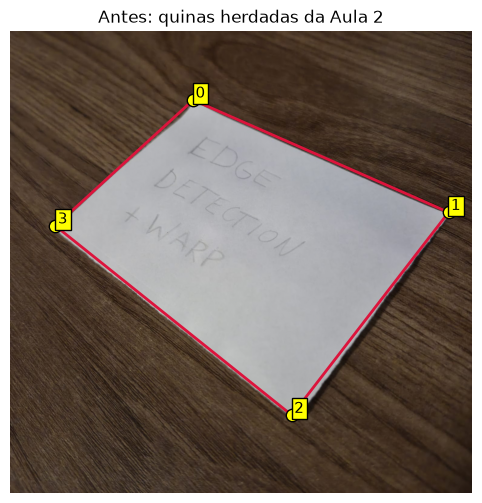

Matriz H:
 [[   0.8477    0.927  -724.1258]
 [  -0.4295    0.9767   37.5214]
 [   0.0003    0.0007    1.    ]]
Erro máximo nas quatro quinas: 2.3743379457759234e-08
Intervalo da saída: (np.float64(0.027450980392156862), np.float64(0.7803921568627451))


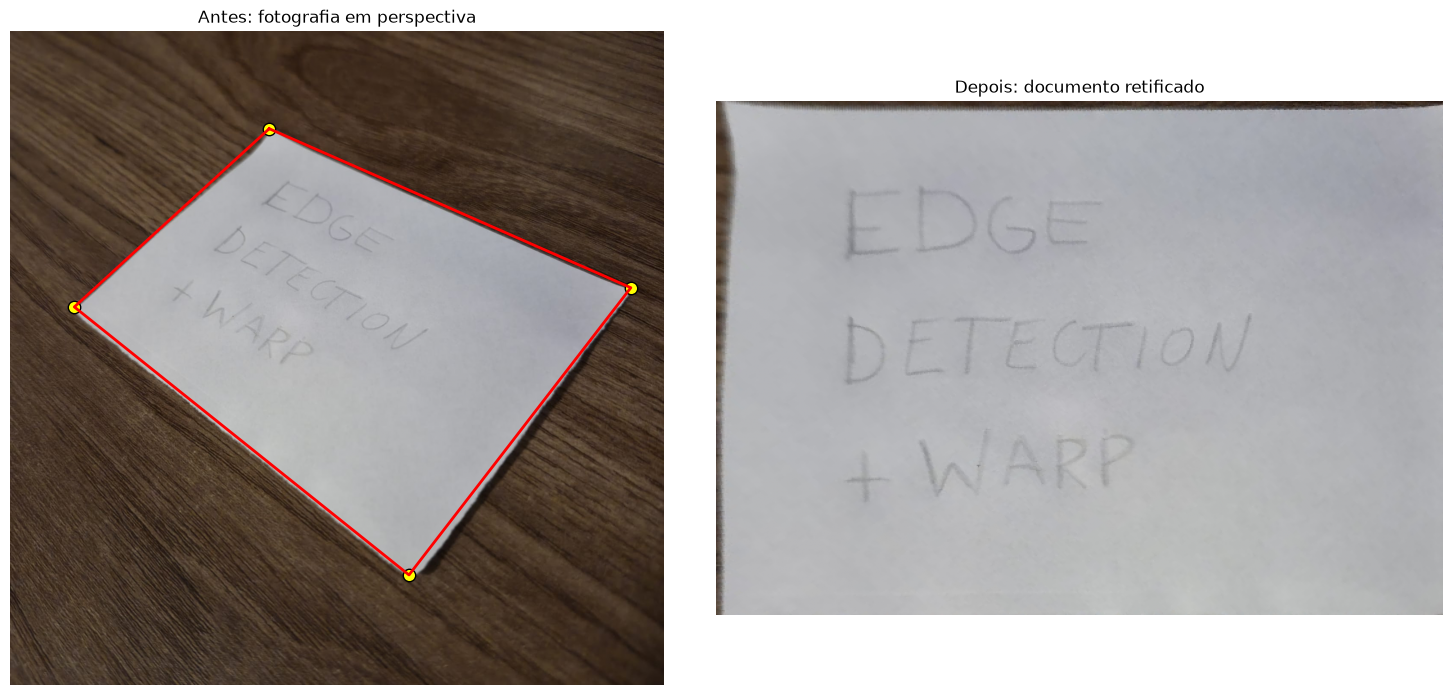

In [10]:
caminho_imagem = 'imgs/edge_warp.jpeg'
imagem_foto = carregar_imagem_rgb(caminho_imagem)
altura_foto, largura_foto = imagem_foto.shape[:2]

# Pontos [x, y] carregados da Aula 2 (topo, direita, base, esquerda).
# Para este documento fotografado, essa ordem coincide com sup-esq, sup-dir, inf-dir, inf-esq.
quinas_origem = np.loadtxt('fragments/extremidades_objeto.txt')

# Proporção de uma folha A4 em orientação paisagem (horizontal).
altura_saida = 400
largura_saida = round(altura_saida * 1.4142)
quinas_destino = np.array([
    [0, 0],
    [largura_saida - 1, 0],
    [largura_saida - 1, altura_saida - 1],
    [0, altura_saida - 1],
], dtype=np.float64)

print('Imagem:', imagem_foto.shape, 'dtype:', imagem_foto.dtype)
print('Saída:', (altura_saida, largura_saida, 3))
print('Quinas carregadas da Aula 2:\n', quinas_origem)
mostrar_pontos(imagem_foto, quinas_origem, 'Antes: quinas herdadas da Aula 2')

H_scanner, A_scanner, S_scanner = calcular_homografia_dlt(quinas_origem, quinas_destino)
imagem_retificada = aplicar_perspectiva_nearest(
    imagem_foto,
    H_scanner,
    nova_altura=altura_saida,
    nova_largura=largura_saida,
)

quinas_reprojetadas = aplicar_homografia(quinas_origem, H_scanner)
erro_scanner = np.max(np.linalg.norm(quinas_reprojetadas - quinas_destino, axis=1))
print('Matriz H:\n', np.round(H_scanner, 6))
print('Erro máximo nas quatro quinas:', erro_scanner)
print('Intervalo da saída:', (imagem_retificada.min(), imagem_retificada.max()))

_fig, eixos = plt.subplots(1, 2, figsize=(15, 7))
eixos[0].imshow(imagem_foto)
pontos_fechados = np.vstack([quinas_origem, quinas_origem[0]])
eixos[0].plot(pontos_fechados[:, 0], pontos_fechados[:, 1], 'r-', linewidth=2)
eixos[0].scatter(quinas_origem[:, 0], quinas_origem[:, 1], c='yellow', edgecolors='black', s=80)
eixos[0].set_title('Antes: fotografia em perspectiva')
eixos[1].imshow(imagem_retificada)
eixos[1].set_title('Depois: documento retificado')
for eixo in eixos:
    eixo.axis('off')
plt.tight_layout()
plt.show()


## 7. Testes e leitura crítica do resultado

Os testes abaixo verificam propriedades matemáticas, não apenas se o código terminou:

- a homografia identidade preserva pontos;
- a homografia calculada reprojeta as quatro correspondências;
- a imagem retificada mantém o shape esperado;
- os valores continuam no intervalo de exibição `[0, 1]`.

A qualidade visual depende diretamente da precisão das quinas. Uma diferença de poucos pixels pode alterar bastante o resultado quando a fotografia tem perspectiva forte.


In [15]:
# Teste 1: identidade geométrica.
pontos_identidade = np.array([[0, 0], [10, 0], [10, 10], [0, 10]], dtype=np.float64)
H_identidade, _, _ = calcular_homografia_dlt(pontos_identidade, pontos_identidade)
assert np.allclose(H_identidade, np.eye(3), atol=1e-10)

# Teste 2: as correspondências usadas para calcular H devem ser recuperadas.
# A tolerância considera arredondamentos da SVD em coordenadas de imagem grandes.
assert erro_scanner < 1e-6

# Teste 3: contrato da saída.
assert imagem_retificada.shape == (altura_saida, largura_saida, 3)
assert imagem_retificada.dtype == np.float64
assert np.all((imagem_retificada >= 0.0) & (imagem_retificada <= 1.0))

print('Identidade: passou')
print('Reprojeção das quinas: passou')
print('Shape, dtype e intervalo da saída: passaram')

Identidade: passou
Reprojeção das quinas: passou
Shape, dtype e intervalo da saída: passaram


## Conclusão e próximos passos

Hoje vimos que o efeito scanner é uma sequência de operações matriciais:

1. localizar as quatro quinas do documento (herdadas da Aula 2);
2. associar essas quinas a um retângulo de destino;
3. resolver a homografia com DLT e SVD;
4. percorrer o destino e consultar a origem com $H^{-1}$;
5. interpolar a cor e construir a imagem plana.

A homografia descreve corretamente uma transformação entre dois planos. Ela não corrige objetos dobrados, páginas com relevo ou deformações tridimensionais reais.

### Exercícios

1. Troque `Nearest Neighbor` por interpolação bilinear.
2. Compare diferentes escolhas para as quatro quinas.
3. O heurístico de extremos por eixo (usado na ponte com a Aula 2) falha em objetos não convexos, ou quando o objeto não está suficientemente rotacionado. Implemente uma estimativa mais robusta das quatro quinas usando interseção de retas ajustadas ao mapa de bordas.
4. Teste a robustez do heurístico: rotacione ou recorte a imagem de entrada e verifique em que ponto os "quatro extremos" deixam de coincidir com os quatro cantos reais.
5. Compare o resultado com uma imagem de referência plana e calcule o erro médio de reconstrução.

A biblioteca pronta pode esconder essas operações, mas a matemática continua sendo a mesma: coordenadas homogêneas, transformações elementares compostas em matrizes, uma homografia geral e uma amostragem inversa.
